In [424]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import butter, filtfilt
import pickle
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
from scipy.signal import resample_poly

In [425]:
import matplotlib.pyplot as plt

WESAD_LABELS = {0: "Transient", 1: "Baseline", 2: "Stress", 3: "Amusement", 4: "Meditation", 5: 'Ignore', 6: 'Ignore', 7: 'Ignore'}
WESAD_COLORS = {0: "lightgray", 1: "tab:blue", 2: "tab:red", 3: "tab:green", 4: "tab:purple"}

def plot_signal_by_label(
    df,
    signal_col,
    label_col,
    title=None,
    label_names=None,
    label_colors=None,
    figsize=(14, 4),
    linewidth=1.2,
    xlabel="Sample",
    ylabel=None,
    ax=None,
):
    """
    Plot a signal, coloured by the label at each point.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain `signal_col` and `label_col`.
    signal_col, label_col : str
        Column names for the signal and its labels.
    title : str, optional
        Plot title. Defaults to "<signal_col> by <label_col>".
    label_names : dict, optional
        Maps label value -> legend text, e.g. {1: "Baseline"}.
    label_colors : dict, optional
        Maps label value -> colour. Missing labels fall back to tab10.
    ax : matplotlib Axes, optional
        Draw on an existing axes instead of creating a new figure.

    Returns
    -------
    ax : matplotlib Axes
    """
    label_names = label_names or {}
    label_colors = label_colors or {}

    if ax is None:
        _, ax = plt.subplots(figsize=figsize)

    # Fallback colours for any label without an explicit one
    cmap = plt.get_cmap("tab10")
    unique_labels = sorted(df[label_col].unique())
    colors = {
        lab: label_colors.get(lab, cmap(i % 10))
        for i, lab in enumerate(unique_labels)
    }

    # Identify contiguous runs of the same label
    run_id = (df[label_col] != df[label_col].shift()).cumsum()
    seen = set()

    for _, chunk in df.groupby(run_id):
        lab = chunk[label_col].iloc[0]

        # Include one extra point so neighbouring segments connect with no gap
        pos_start = df.index.get_loc(chunk.index[0])
        pos_end = df.index.get_loc(chunk.index[-1])
        seg = df.iloc[pos_start : min(pos_end + 2, len(df))]

        ax.plot(
            seg.index,
            seg[signal_col],
            color=colors[lab],
            linewidth=linewidth,
            label=label_names.get(lab, f"Label {lab}") if lab not in seen else None,
        )
        seen.add(lab)

    ax.set_title(title or f"{signal_col} by {label_col}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel or signal_col)
    ax.legend(title="Label")
    return ax

Call in WESAD EDA data from `load_eda.ipnyb` and conducts Buttersworth low-pass on participant's EDA signals. Final dataframe produced ``

- normal_flag = 1: normalization applied
- normal_flag = 0: not applied

In [426]:
normal_flag = 1 # or 0

In [427]:
with open("../Data/wesad_eda/wesad_subject_list.pkl", "rb") as f:
    wesad_data = pickle.load(f)
wesad_data[0]

,S15_EDA,S15_Label
0,0.220298,0
1,0.170407,0
2,0.189596,0
3,0.151218,0
4,0.166569,0
...,...,...
21003,0.454401,0
21004,0.455680,0
21005,0.454401,0
21006,0.451842,0


The raw EDA signal as a baseline of S15

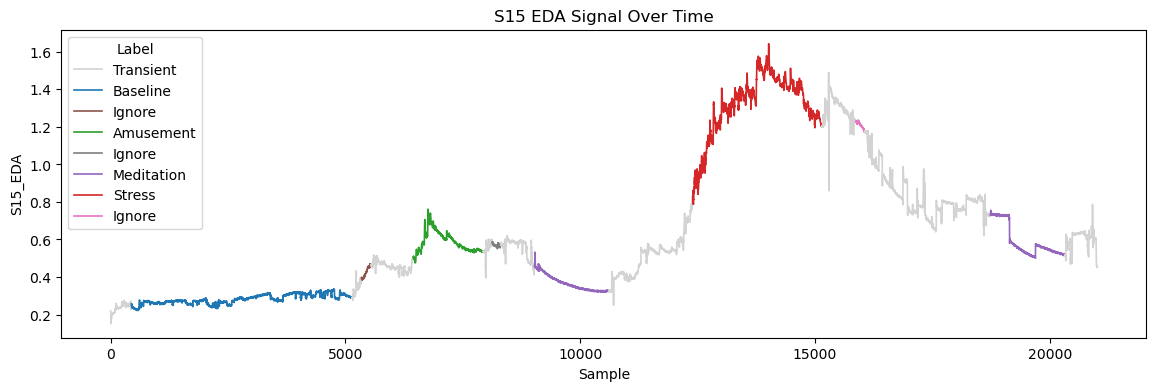

In [428]:
plot_signal_by_label(
    wesad_data[0],
    signal_col="S15_EDA",
    label_col="S15_Label",
    title="S15 EDA Signal Over Time",
    label_names=WESAD_LABELS,
    label_colors=WESAD_COLORS,
)
plt.show()

Buttersworth filter applied to one signal, S15
Parameter choice is based on Nyquist-Shannon sampling theorem, cut off was decided following Hosseini paper

In [429]:
#Extract out Partcipant 15's EDA signal for processing
s15 = wesad_data[0]
s15_eda = s15.iloc[:,0]
#Parameters for Buttersworth filter
#Frequency sampling rate
fs = 4.0
#Frequency Cutoff, conservative, most SCR lives below 0.5 but phasic features tend to live in 1-1.5 land and Nyquist means we have to keep threshold below 2 so conservative cleaning
fc = 1.5
#Cutoff rate rationalized for nyquist
cutoff = (2*fc)/fs          
#Creates the denominator and numerator for the filtering of the signal in the Buttersworth transfer function, low-pass filter
b, a = butter(4, cutoff, btype='low')
# Apply filter onto participant 15
s15_filtered = filtfilt(b, a, s15_eda)

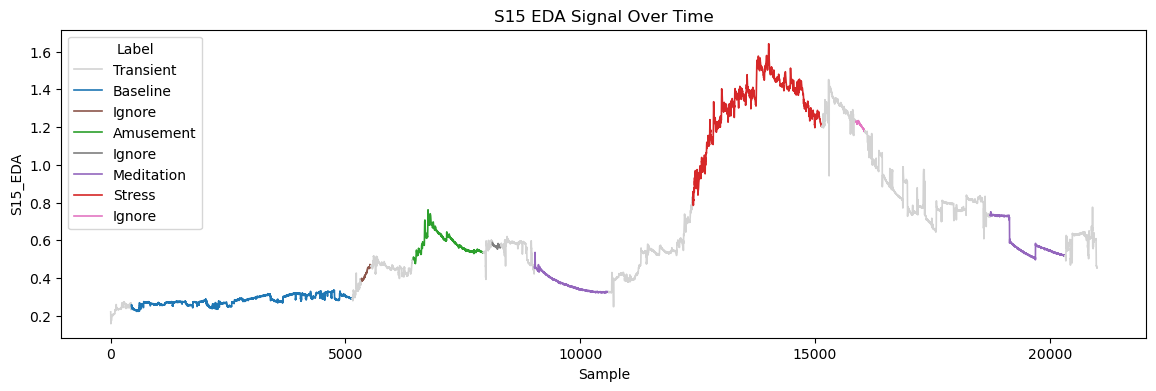

In [430]:
s15_label = s15.iloc[:, 1]
s15_eda = pd.DataFrame(
    {"S15_EDA": s15_filtered, "S15_Label": s15_label.values}, index=s15.index
)

plot_signal_by_label(
    s15_eda,
    signal_col="S15_EDA",
    label_col="S15_Label",
    title="S15 EDA Signal Over Time",
    label_names=WESAD_LABELS,
    label_colors=WESAD_COLORS,
)
plt.show()

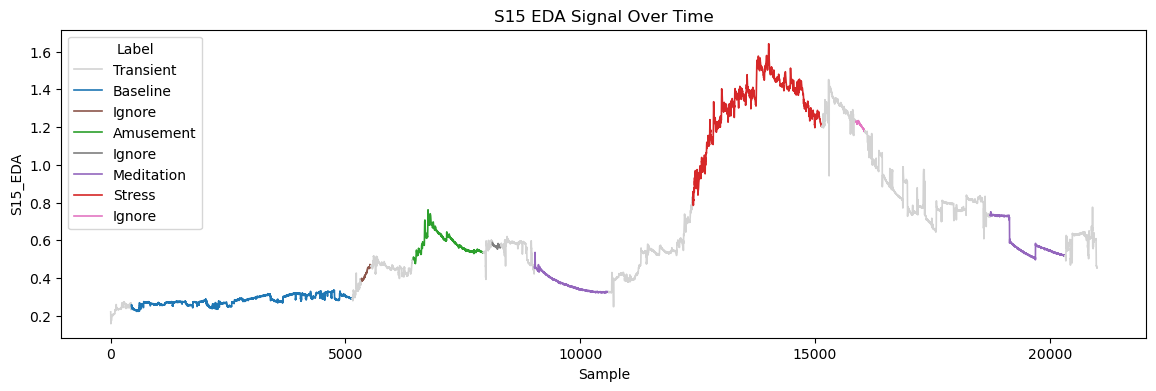

In [431]:
s15_label = s15["S15_Label"]

s15_eda_df = pd.DataFrame(
    {"S15_EDA": s15_filtered, "S15_Label": s15_label.values}, index=s15.index
)

plot_signal_by_label(
    s15_eda_df,
    signal_col="S15_EDA",
    label_col="S15_Label",
    title="S15 EDA Signal Over Time",
    label_names=WESAD_LABELS,
    label_colors=WESAD_COLORS,
)
plt.show()

In [432]:
#np.abs(s15_eda[0] - s15_filtered[0]).sum()

Loop through all EDA signals to apply Buttersworth filter and per subject min-max normalization and create a dataframe

In [433]:
def upsample_subject(participant_df, orig_fs=4, target_fs=8):
    eda = participant_df.iloc[:, 0].values
    label = participant_df.iloc[:, 1].values

    up, down = target_fs, orig_fs  # 8/4 = 2x
    eda_up = resample_poly(eda, up, down)

    # repeat each label to match the new sample count (nearest-hold, not interpolation)
    factor = target_fs // orig_fs
    label_up = np.repeat(label, factor)[:len(eda_up)]

    return pd.DataFrame({
        participant_df.columns[0]: eda_up,
        participant_df.columns[1]: label_up
    })

In [434]:
filtered_signals = []


for i in range(len(wesad_data)):
    #participant_data = upsample_subject(wesad_data[i])
    participant_data = wesad_data[i]
    participant_signal = participant_data.iloc[:, 0]
    
    # Butterworth filter applied
    sos = signal.butter(N=4, Wn=2.5, btype='low', output='sos', fs=8)
    participant_filtered = signal.sosfilt(sos, participant_signal)
    
    #Apply normaliziation, reshape with a column for row ID then flatten back down to only the original signal
    if normal_flag == 1:
        participant_filtered = MinMaxScaler().fit_transform(participant_filtered.reshape(-1, 1)).ravel()
    
    # Build dataframe and append
    subject_id = participant_data.columns[0].split('_')[0]
    filtered_dataframe = pd.DataFrame({
        f'{subject_id}_EDA': participant_filtered,
        f'{subject_id}_Label': participant_data.iloc[:, 1]
    })
    filtered_signals.append(filtered_dataframe)

Combine all dataframes into onem remove NAs based on the shortest signal, to convert to a pickle for future processing

In [435]:
filtered_eda = pd.concat(filtered_signals, axis=1)
filtered_eda_na_omitted = filtered_eda.dropna()
filtered_eda_na_omitted.head()

,S15_EDA,S15_Label,S7_EDA,S7_Label,S3_EDA,S3_Label,S2_EDA,S2_Label,S14_EDA,S14_Label,...,S4_EDA,S4_Label,S13_EDA,S13_Label,S5_EDA,S5_Label,S9_EDA,S9_Label,S6_EDA,S6_Label
0,0.000000,0.0,0.000000,0.0,0.016044,0.0,0.097471,0.0,0.011914,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.037751,0.0,0.033865,0
1,0.073305,0.0,0.485077,0.0,0.178527,0.0,0.492093,0.0,0.175268,0.0,...,0.031140,0.0,0.366758,0.0,0.065186,0.0,0.144301,0.0,0.199618,0
2,0.116746,0.0,0.854691,0.0,0.319746,0.0,0.769926,0.0,0.278055,0.0,...,0.053885,0.0,0.628746,0.0,0.109112,0.0,0.224244,0.0,0.323051,0
3,0.083819,0.0,0.729083,0.0,0.296441,0.0,0.620082,0.0,0.191334,0.0,...,0.044419,0.0,0.511660,0.0,0.085603,0.0,0.197046,0.0,0.275535,0
4,0.062718,0.0,0.609167,0.0,0.256728,0.0,0.491979,0.0,0.120382,0.0,...,0.035439,0.0,0.421939,0.0,0.063158,0.0,0.172040,0.0,0.231554,0


In [436]:
filtered_eda_na_omitted.to_csv("../Data/wesad_eda/filtered_eda_signals.csv", index=False)

Checking visually why they end at different activity label markers, time_scale appears to be relatively similar but slight cut off at the end, unsure if it is a complete problem

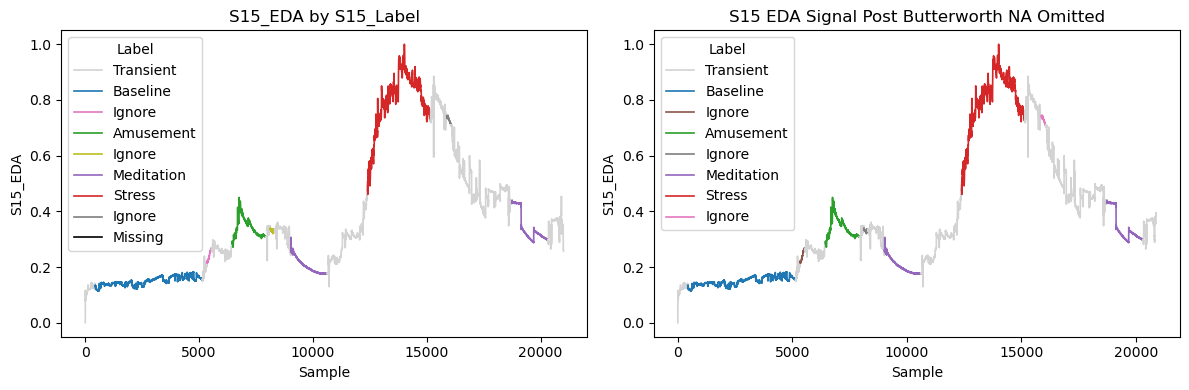

In [437]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

plot_signal_by_label(
    filtered_eda.fillna({filtered_eda.columns[1]: -1}),
    signal_col=filtered_eda.columns[0],
    label_col=filtered_eda.columns[1],
    label_names={**WESAD_LABELS, -1: "Missing"},
    label_colors={**WESAD_COLORS, -1: "black"},
    ax=ax1,
)

plot_signal_by_label(
    filtered_eda_na_omitted,
    signal_col=filtered_eda_na_omitted.columns[0],
    label_col=filtered_eda_na_omitted.columns[1],
    title="S15 EDA Signal Post Butterworth NA Omitted",
    label_names=WESAD_LABELS,
    label_colors=WESAD_COLORS,
    ax=ax2,
)

plt.tight_layout()
plt.show()